# Supply at Risk: the walkthrough

*The project from the [README](../README.md), one step at a time, with the code and the output under each step.*

Every number here is recomputed from saved results in `data_local/`. Nothing is refit, the holdout is not rerun, and
nothing in the frozen analysis is written. Outputs are aggregates only: no listing or host ids are printed, because
listing-level data isn't part of this repository.

It starts from the corrected data. How the raw source was kept read-only and cleaned is in the README (its Steps 1
and 2), so the steps here begin with the label.

To run it, build `data_local/` with `scripts/reproduce.sh` (it needs the source data; see the README), then run this
notebook top to bottom from `notebooks/`. It takes about a minute.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT / "src"))

import business
import freeze
from backtest import block_bootstrap_ci
from db import CITIES
from features import ALLOWLIST, FORBIDDEN
from model import RULES

LOCAL = PROJECT / "data_local"
BT = LOCAL / "backtest"
LABELS = LOCAL / "labels"
con = duckdb.connect()
q = lambda sql: con.execute(sql).df()

# reference palette (dataviz skill), the same tokens as scripts/make_figures.py
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 8.5, "axes.titlesize": 10, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.titlepad": 12, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "legend.labelcolor": INK2,
})
pd.options.display.float_format = "{:,.3f}".format
pct = lambda ax: ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

## The dataset

The corrected copy of the public [Inside Airbnb](https://insideairbnb.com/get-the-data/) snapshots (CC BY 4.0) for six
US markets, with every fix flagged on the row it changed. Monthly until 2022, quarterly after.

In [2]:
schedule = q(f"SELECT * FROM '{LABELS / 'schedule.parquet'}'").assign(market=lambda d: d.city_id.map(CITIES))
rows = q(f"SELECT count(*) AS n FROM '{LOCAL / 'listings_6city_clean.parquet'}' WHERE NOT id_imprecise").n[0]
print(f"{len(schedule)} snapshots, {schedule.snap.min():%b %Y} to {schedule.snap.max():%b %Y}, "
      f"{rows:,} listing-snapshot rows")
schedule.groupby("market").agg(snapshots=("snap", "size"), first=("snap", "min"), last=("snap", "max"),
                               median_listings=("n_listings", "median")).astype({"median_listings": int})

563 snapshots, May 2015 to Jun 2026, 4,191,819 listing-snapshot rows


,snapshots,first,last,median_listings
market,,,,
Austin,96,2015-05-23,2026-06-22,11250
Denver,85,2016-06-07,2026-06-30,4511
Nashville,96,2015-10-03,2026-06-26,6148
New Orleans,101,2015-06-05,2026-06-16,6276
San Diego,93,2015-11-07,2026-06-27,11496
Seattle,92,2015-11-08,2026-06-15,6247


## First, the one rule that shapes everything

**A prediction made on date *t* may use only what was known on date *t*.**

The first place it bites: a snapshot's file date isn't when its data was known. Rows keep arriving for days after it,
so every prediction date carries a separate **decision date**, when the snapshot finished collecting.

In [3]:
pdates = q(f"SELECT * FROM '{LABELS / 'prediction_dates.parquet'}'")
lag = (pdates.decision_date - pdates.t).dt.days
print(f"{len(pdates)} quarterly prediction dates across {pdates.city_id.nunique()} markets")
print(f"{(lag == 0).sum()} finished collecting on their file date; the other {(lag > 0).sum()} took "
      f"1 to {lag.max()} days (median {lag[lag > 0].median():.0f})")

239 quarterly prediction dates across 6 markets
105 finished collecting on their file date; the other 134 took 1 to 21 days (median 1)


Everything below runs on decision dates, not file dates.

## Step 1 — Decide what "gone" means before you predict it

A listing present at prediction date *t* is **`absent_confirmed`** if it's missing from the snapshot nearest
*t* + 180 days **and** from the one nearest *t* + 270 days (±45 days each). A label becomes training data only once
it's **final**: nothing still to arrive could change it.

In [4]:
LAB = LABELS / "labels.parquet"
(q(f"SELECT outcome, label_status, count(*) AS n FROM '{LAB}' GROUP BY ALL")
   .pivot_table(index="outcome", columns="label_status", values="n", aggfunc="sum", fill_value=0, margins=True))

label_status,final,provisional,All
outcome,,,
absent_confirmed,315921,3182,319103
insufficient_followup,170179,125113,295292
observed,1233455,17424,1250879
All,1719555,145719,1865274


`insufficient_followup` means the checkpoints fell on missing or unusable snapshots. Those rows are never guessed at;
they drop out. Among final, eligible labels, here is the share absent at each quarter:

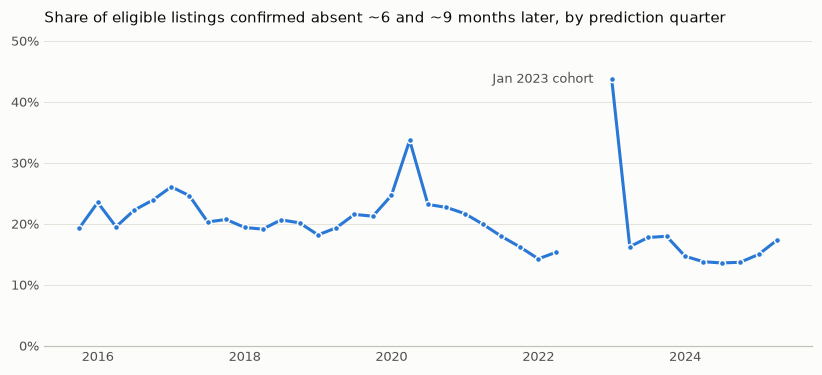

In [5]:
by_quarter = q(f'''
    SELECT date_trunc('quarter', t) AS quarter, count(*) AS listings,
           avg((outcome = 'absent_confirmed')::INT) AS absent_rate
    FROM '{LAB}'
    WHERE eligible_main AND label_final AND outcome IN ('absent_confirmed', 'observed')
    GROUP BY 1 ORDER BY 1
''')
full = by_quarter.set_index("quarter").asfreq("QS")      # quarters with no usable follow-up stay empty

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(full.index, full.absent_rate, color=BLUE, lw=2, marker="o", ms=4, mec=SURFACE, mew=1)
jan23 = full.absent_rate.idxmax()
ax.annotate("Jan 2023 cohort", (jan23, full.absent_rate.max()), xytext=(-12, 0), textcoords="offset points",
            ha="right", va="center", color=INK2)
ax.set_ylim(0, 0.5); pct(ax)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Share of eligible listings confirmed absent ~6 and ~9 months later, by prediction quarter")
plt.show()

Most quarters sit between 14% and 26%. The gap is the stretch where the follow-up checkpoints had no usable snapshot.
Two quarters stand out: spring 2020, as COVID hit, and the Jan 2023 cohort, which gets its own section at the end.

***Check:*** *a forward-in-time test feeds data in 15 days at a time and confirms that a final label never changes
([tests/test_label.py](../tests/test_label.py)).*

## Step 2 — Build features only from what you knew that day

In [6]:
kinds = pd.Series(ALLOWLIST).value_counts()
print(f"{len(ALLOWLIST)} approved predictors: " + ", ".join(f"{n} {k}" for k, n in kinds.items()))
print(f"{len(FORBIDDEN)} fields banned outright, e.g. {sorted(FORBIDDEN & {'outcome', 'label_final_at', 'host_changed', 'list_id'})}")

61 approved predictors: 49 numeric, 8 binary, 4 categorical
121 fields banned outright, e.g. ['host_changed', 'label_final_at', 'list_id', 'outcome']


One feature carries more than its share: **presence rate over the past year**, the share of usable snapshots that
contained the listing. It's a rate, so it means the same thing in the monthly and quarterly eras.

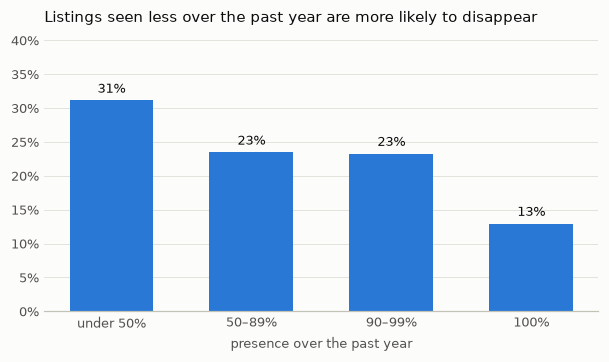

,listings,absent_rate
presence,,
under 50%,363824,0.311
50–89%,198947,0.235
90–99%,36631,0.233
100%,651966,0.129


In [7]:
presence = q(f'''
    SELECT CASE WHEN f.presence_rate_365 < 0.5 THEN 'under 50%'
                WHEN f.presence_rate_365 < 0.9 THEN '50–89%'
                WHEN f.presence_rate_365 < 1 THEN '90–99%'
                ELSE '100%' END AS presence,
           count(*) AS listings, avg((l.outcome = 'absent_confirmed')::INT) AS absent_rate
    FROM '{LAB}' l JOIN '{LOCAL / "features.parquet"}' f USING (city_id, list_id, t)
    WHERE l.eligible_main AND l.label_final AND l.outcome IN ('absent_confirmed', 'observed')
    GROUP BY 1
''').set_index("presence").loc[["under 50%", "50–89%", "90–99%", "100%"]]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bars = ax.bar(presence.index, presence.absent_rate, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in presence.absent_rate], padding=3, color=INK)
ax.set_ylim(0, 0.4); pct(ax); ax.set_xlabel("presence over the past year")
ax.set_title("Listings seen less over the past year are more likely to disappear")
plt.show()
presence

***Check:*** *the feature tests rebuild every prediction date from data truncated at t, and from data whose later rows
were changed, dropped and added to; each must match the full build exactly. `tests/mutation_check.py` plants 24 bugs
in the SQL and confirms the suite catches every one.*

## Step 3 — Beat a simple rule first, then train two models

Four rules a retention analyst could build in a spreadsheet:

In [8]:
print("\n".join(RULES))

days_since_last_review
low_presence_365
low_review_rate_90
calendar_blocked


The best of them on the development folds, `low_presence_365`, is the bar to clear. Then **logistic regression**
(simple, explainable) and **LightGBM** (heavier, has to earn its place). What LightGBM leans on, averaged over the
holdout folds:

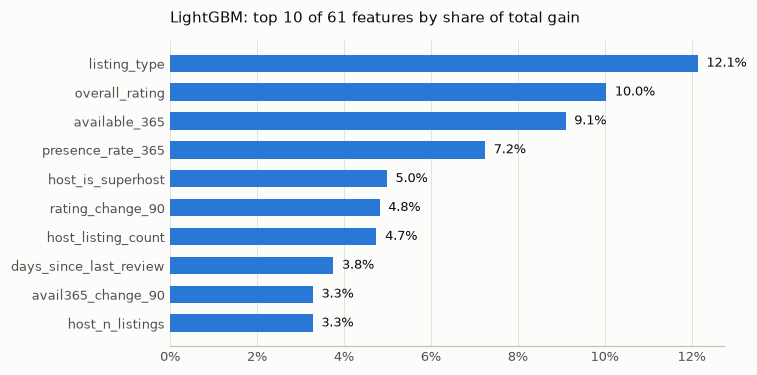

In [9]:
gains = pd.read_csv(BT / "holdout_gains.csv", index_col=0).mean(axis=1).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(gains.index, gains.values, color=BLUE, height=0.6)
for y, v in enumerate(gains.values):
    ax.text(v + 0.002, y, f"{v:.1%}", va="center", color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("LightGBM: top 10 of 61 features by share of total gain")
plt.show()

Listing type, rating, availability and presence do most of the work. These are predictive associations, not reasons
hosts leave.

## Step 4 — Evaluate the way it will be used

The team calls 500 hosts a quarter, so the metric is **host precision@500**: of the 500 highest-ranked hosts, the share
with at least one listing that later disappears. One fold per quarter, trained only on labels final before it starts.

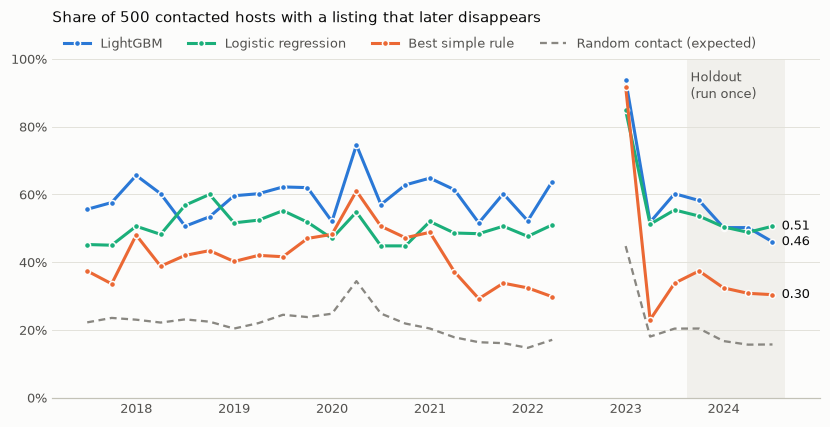

In [10]:
def host_p500(name):
    m = pd.read_csv(BT / f"{name}_metrics.csv").query("variant == 'retain'")
    f = pd.read_csv(BT / f"{name}_folds.csv").query("variant == 'retain'")
    w = m.pivot(index="quarter", columns="model", values="host_p@500")
    return w.assign(random=f.set_index("quarter")["host_base_rate"], split=name)

p500 = pd.concat([host_p500("dev"), host_p500("holdout")])
p500.index = pd.PeriodIndex(p500.index, freq="Q")
p500 = p500.reindex(pd.period_range(p500.index.min(), p500.index.max(), freq="Q"))
RULE = "rule:low_presence_365"
SERIES = {"lgbm": ("LightGBM", BLUE), "lr": ("Logistic regression", AQUA), RULE: ("Best simple rule", ORANGE)}

x = np.arange(len(p500))
fig, ax = plt.subplots(figsize=(9, 4))
hold = np.flatnonzero(p500.split == "holdout")
ax.axvspan(hold[0] - 0.5, hold[-1] + 0.5, color="#f1f0ec", lw=0, zorder=0)
ax.text(hold[0] - 0.35, 0.97, "Holdout\n(run once)", color=INK2, va="top")
for col, (label, color) in SERIES.items():
    ax.plot(x, p500[col], color=color, lw=2, marker="o", ms=4, mec=SURFACE, mew=1, label=label, zorder=3)
    ax.annotate(f"{p500[col].iloc[-1]:.2f}", (x[-1], p500[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.plot(x, p500.random, color=MUTED, lw=1.5, ls=(0, (3, 2)), label="Random contact (expected)", zorder=2)
ticks = [i for i, p in enumerate(p500.index) if p.quarter == 1]
ax.set_xticks(ticks, [str(p500.index[i].year) for i in ticks])
ax.set_ylim(0, 1); pct(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.1), ncol=4)
ax.set_title("Share of 500 contacted hosts with a listing that later disappears", pad=24)
plt.show()

In [11]:
dev = p500[p500.split == "dev"]
lift = dev.lgbm - dev[RULE]
_, lo, hi = block_bootstrap_ci(lift.to_numpy())
print(f"Development, {len(dev)} quarters: LightGBM {dev.lgbm.mean():.2f}, rule {dev[RULE].mean():.2f}, "
      f"logistic {dev.lr.mean():.2f}")
print(f"LightGBM − rule: {100 * lift.mean():+.1f} pp on average, better in {(lift > 0).sum()}/{len(lift)} quarters "
      f"(block-bootstrap 95% CI {100 * lo:.1f} to {100 * hi:.1f} pp)")

Development, 23 quarters: LightGBM 0.61, rule 0.43, logistic 0.52
LightGBM − rule: +17.9 pp on average, better in 23/23 quarters (block-bootstrap 95% CI 13.9 to 20.8 pp)


LightGBM clears the rule in every development quarter. The 2023 spike lifts every line at once, including random
contact, because the base rate itself jumped.

## Step 5 — Freeze everything, then open the holdout once

Before the holdout ran, every setting and the hash of every analysis file went into `config/analysis_freeze.json`.
`freeze.verify()` is the same check the holdout run had to pass:

In [12]:
spec = freeze.verify()
print(f"freeze intact: {len(spec['file_sha256'])} files unchanged since {spec['frozen_on']}; "
      f"holdout {spec['holdout']['start']} to {spec['holdout']['end']} (end exclusive)")

freeze intact: 16 files unchanged since 2026-10-20; holdout 2023-10-01 to 2024-10-01 (end exclusive)


In [13]:
names = {"random": "Random", RULE: "Best simple rule", "lr": "Logistic regression", "lgbm": "LightGBM"}
pd.DataFrame({
    "development (23 quarters)": dev[list(names)].mean(),
    "holdout (4 quarters, run once)": p500[p500.split == "holdout"][list(names)].mean(),
}).rename(index=names)

,development (23 quarters),"holdout (4 quarters, run once)"
model,,
Random,0.225,0.171
Best simple rule,0.426,0.328
Logistic regression,0.521,0.508
LightGBM,0.606,0.512


In [14]:
hold = p500[p500.split == "holdout"]
hm = pd.read_csv(BT / "holdout_metrics.csv").query("variant == 'retain'").groupby("model")["host_p@100"].mean()
print("LightGBM − rule, per holdout quarter (pp):", ", ".join(f"{q}: {100 * d:+.1f}" for q, d in (hold.lgbm - hold[RULE]).items()))
print(f"Extra hosts per 500 contacts vs the rule: {500 * (hold.lgbm - hold[RULE]).mean():.0f}")
print(f"At 100 contacts: LightGBM {hm['lgbm']:.2f} vs logistic regression {hm['lr']:.2f}")

LightGBM − rule, per holdout quarter (pp): 2023Q4: +20.8, 2024Q1: +17.8, 2024Q2: +19.4, 2024Q3: +15.6
Extra hosts per 500 contacts vs the rule: 92
At 100 contacts: LightGBM 0.64 vs logistic regression 0.49


**+18.4 pp** over the rule in all 4 holdout quarters, about **90 more hosts per 500 calls**. Logistic regression nearly
ties LightGBM at 500 contacts; the heavier model keeps a clear lead only on a tighter budget.

## Step 6 — Turn probabilities into a contact list

Each listing gets a value proxy, *V*: twelve months of booking value at its asking price, with bookings estimated from
reviews. (A proxy, not realized revenue.) Hosts are then ranked four ways and compared on the booking value that
actually disappeared among the hosts each ranking picks.

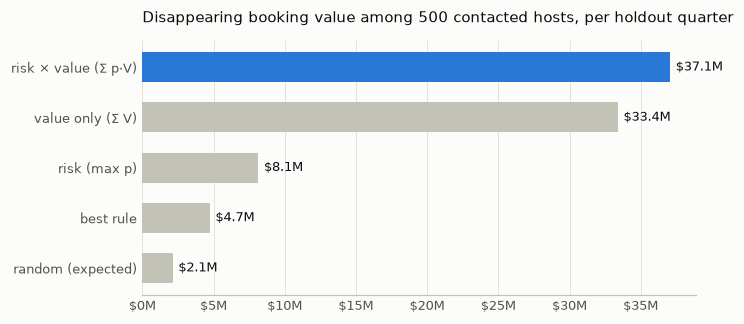

,precision,captured ($M)
strategy,,
random (expected),0.171,2.100
best rule,0.328,4.700
risk (max p),0.511,8.100
value only (Σ V),0.520,33.400
risk × value (Σ p·V),0.613,37.100


In [15]:
biz = pd.read_csv(BT / "holdout_business.csv").query("variant == 'retain' and value_scenario == 'central' and k == 500")
strategies = (biz.groupby("strategy").agg(precision=("precision", "mean"), captured=("captured", "mean"))
                 .sort_values("captured"))
BEST = "risk × value (Σ p·V)"

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(strategies.index, strategies.captured / 1e6, height=0.6,
        color=[BLUE if s == BEST else AXIS for s in strategies.index])
for y, v in enumerate(strategies.captured / 1e6):
    ax.text(v + 0.4, y, f"${v:.1f}M", va="center", color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.0f}M"))
ax.set_title("Disappearing booking value among 500 contacted hosts, per holdout quarter")
plt.show()
strategies.assign(captured=lambda d: (d.captured / 1e6).round(1)).rename(columns={"captured": "captured ($M)"})

In [16]:
w = biz.pivot(index="quarter", columns="strategy", values="captured")
gain = w[BEST] / w["value only (Σ V)"] - 1
print(f"Σ p·V vs value only: {gain.mean():+.0%} captured value on average, better in {(gain > 0).sum()}/{len(gain)} quarters")

Σ p·V vs value only: +11% captured value on average, better in 4/4 quarters


Risk adds a real but modest gain on top of "call the biggest accounts".

## Step 7 — Translate it for the retention lead

Who ends up on each list, by portfolio size:

In [17]:
preds = business.load("holdout")
listings = business.value_proxy(preds[preds.variant == "retain"], business.REVIEW_SHARES["central"])
hosts = business.host_table(listings, "lgbm", RULE)
(pd.concat([business.by_portfolio(hosts, 500, col).assign(ranking=name)
            for name, col in [("risk (max p)", "risk_max"), (BEST, "exposure")]])
   [["ranking", "bucket", "contacted_share", "precision", "captured_value_share"]]
   .rename(columns={"bucket": "listings per host"}))

,ranking,listings per host,contacted_share,precision,captured_value_share
0,risk (max p),1,0.522,0.411,0.012
1,risk (max p),2–5,0.291,0.509,0.093
2,risk (max p),6–20,0.116,0.727,0.232
3,risk (max p),21+,0.071,0.908,0.663
0,risk × value (Σ p·V),1,0.055,0.255,0.025
1,risk × value (Σ p·V),2–5,0.178,0.368,0.090
2,risk × value (Σ p·V),6–20,0.452,0.597,0.323
3,risk × value (Σ p·V),21+,0.315,0.835,0.562


In [18]:
captured = w[BEST].mean()
pd.DataFrame([{"prevents": f"{p:.0%}", "take rate": f"{t:.0%}",
               "break-even cost per contact": f"${business.breakeven_cost(captured, 500, p, t):,.0f}"}
              for p in (0.05, 0.10, 0.20) for t in (0.10, 0.15)])

,prevents,take rate,break-even cost per contact
0,5%,10%,$371
1,5%,15%,$556
2,10%,10%,$741
3,10%,15%,"$1,112"
4,20%,10%,"$1,483"
5,20%,15%,"$2,224"


Four lines for the meeting:

- **About half** of the hosts on the list go on to lose a listing, against **a third** with the best rule.
- Risk × value captures **+11%** more of the disappearing booking value than ranking by size alone.
- Hosts with **21+ listings** hold **56–66%** of the captured value.
- Outreach breaks even at **$370 to $2,200 per contact**, depending on prevention and take rates nobody knows yet.

## Step 8 — Design the test that proves it works

Everything so far measures targeting. Whether a call keeps a listing needs a host-randomized experiment on the top
1,000 hosts per quarter by Σ p·V:

In [19]:
top1000 = business.top_k(hosts, "exposure", 1000)
p = top1000.hit.mean()
print(f"Holdout event rate among the top 1,000 by Σ p·V: {p:.1%}")
pd.DataFrame([{"relative reduction to detect": f"{r:.0%}", "independent hosts per arm": business.hosts_per_arm(p, r),
               "recruitment quarters (500 new per arm)": -(-business.hosts_per_arm(p, r) // 500)}
              for r in (0.05, 0.10, 0.20)])

Holdout event rate among the top 1,000 by Σ p·V: 47.5%


,relative reduction to detect,independent hosts per arm,recruitment quarters (500 new per arm)
0,5%,6919,14
1,10%,1722,4
2,20%,425,1


A 10% reduction needs about **1,722 hosts per arm**: four recruitment quarters, then 9–10 months of follow-up.

## Step 9 — Audit it before anyone ships it

**Are the probabilities usable as probabilities?**

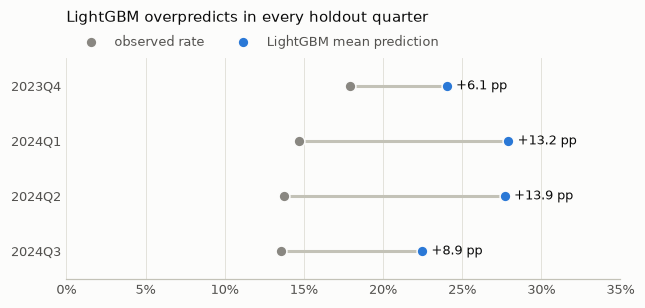

In [20]:
m = pd.read_csv(BT / "holdout_metrics.csv").query("variant == 'retain' and model == 'lgbm'")
f = pd.read_csv(BT / "holdout_folds.csv").query("variant == 'retain'")
cal = m.merge(f, on="quarter")[["quarter", "mean_pred", "base_rate"]].iloc[::-1]

fig, ax = plt.subplots(figsize=(6.5, 2.6))
y = np.arange(len(cal))
ax.hlines(y, cal.base_rate, cal.mean_pred, color=AXIS, lw=2)
ax.scatter(cal.base_rate, y, s=50, color=MUTED, zorder=3, label="observed rate", edgecolor=SURFACE)
ax.scatter(cal.mean_pred, y, s=50, color=BLUE, zorder=3, label="LightGBM mean prediction", edgecolor=SURFACE)
for yi, (pred, obs) in enumerate(zip(cal.mean_pred, cal.base_rate)):
    ax.text(pred + 0.006, yi, f"+{100 * (pred - obs):.1f} pp", va="center", color=INK)
ax.set_yticks(y, cal.quarter); ax.set_xlim(0, 0.35); ax.set_ylim(-0.5, len(cal) - 0.5)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.16), ncol=2)
ax.set_title("LightGBM overpredicts in every holdout quarter", pad=24)
plt.show()

The ranking holds up; dollar forecasts built on raw probabilities would not.

**Could this list have been built on the day?** Markets are scraped on different days, and a quarter's ranking pools
them. Contacted hosts whose ranking used a listing observed after their contact date:

In [21]:
latest = listings.groupby(["quarter", "host_id_at_t"]).decision_date.max().rename("latest_decision")
timed = hosts.join(latest, on=["quarter", "host_id_at_t"])
pd.DataFrame({name: business.top_k(timed, col, 500).assign(late=lambda d: d.latest_decision > d.contact_date)
                                       .groupby("quarter").late.sum()
              for name, col in [("risk (max p)", "risk_max"), (BEST, "exposure")]})

,risk (max p),risk × value (Σ p·V)
quarter,,
2023Q4,24,23
2024Q1,16,24
2024Q2,12,24
2024Q3,12,19


Up to 24 of 500. So the honest name for the result is a **pooled quarterly ranking benchmark**, not a deployable
contact policy.

## The quarter that broke the labels

At every Jan 2023 prediction date, far more listings came out absent than in neighbouring quarters. (Five markets
have one; Denver's quarterly schedule goes from October 2022 straight to June 2023.)

In [22]:
q(f'''
    SELECT city_id, t, count(*) AS listings, avg((outcome = 'absent_confirmed')::INT) AS absent_rate
    FROM '{LAB}'
    WHERE eligible_main AND label_final AND outcome IN ('absent_confirmed', 'observed')
      AND t BETWEEN DATE '2022-12-01' AND DATE '2023-02-28'
    GROUP BY ALL ORDER BY t
''').assign(market=lambda d: d.city_id.map(CITIES)).set_index("market").drop(columns="city_id")

,t,listings,absent_rate
market,,,
New Orleans,2023-01-09,5532,0.372
Austin,2023-01-16,9837,0.497
Nashville,2023-01-20,7324,0.425
San Diego,2023-01-23,10928,0.439
Seattle,2023-01-23,5266,0.409


The strongest clue: for each pair of consecutive snapshots, the share of vanished ids that have a new id with the same
host, neighbourhood, room type and capacity.

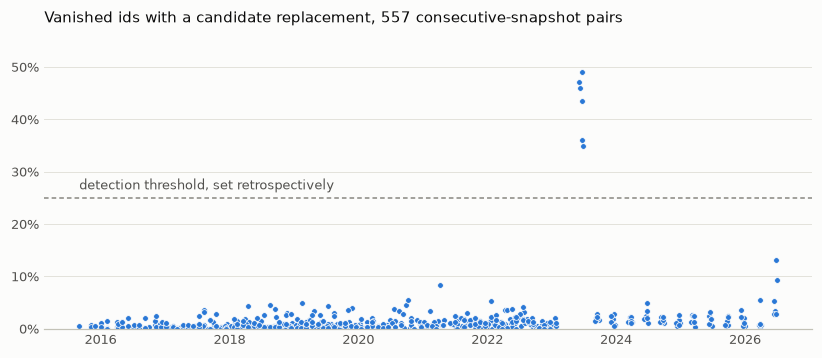

In [23]:
rekey = pd.read_csv(LOCAL / "validation_clean" / "rekey_detection.csv", parse_dates=["snap"])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.scatter(rekey.snap, rekey.rekey_share, s=14, color=BLUE, edgecolor=SURFACE, lw=0.5)
ax.axhline(0.25, color=MUTED, lw=1, ls=(0, (3, 2)))
ax.text(rekey.snap.min(), 0.26, "detection threshold, set retrospectively", color=INK2, va="bottom")
ax.set_ylim(0, 0.55); pct(ax)
ax.set_title(f"Vanished ids with a candidate replacement, {len(rekey)} consecutive-snapshot pairs")
plt.show()

35–49% at the break, against at most 8% in every earlier pair. Even that doesn't establish they're the same
accommodations, or why it happened, so the cause stays **unresolved**. The primary analysis keeps those outcomes; a
prespecified sensitivity variant excludes them. Both were frozen, and they agree:

In [24]:
hm = pd.read_csv(BT / "holdout_metrics.csv").pivot(index=["variant", "quarter"], columns="model", values="host_p@500")
(hm.lgbm - hm[RULE]).unstack("quarter").assign(mean=lambda d: d.mean(axis=1))

quarter,2023Q4,2024Q1,2024Q2,2024Q3,mean
variant,,,,,
exclude,0.216,0.216,0.276,0.222,0.232
retain,0.208,0.178,0.194,0.156,0.184


## What the walkthrough shows

None of the hard parts were the model. They were deciding what "gone" means, keeping the future out of every feature,
and opening the holdout once. Every step above has a reason you can say out loud, and an output that checks it.

The formal write-up: [reports/writeup.md](../reports/writeup.md). The full reports behind each step:
[reports/](../reports/).